# Main Pipeline & Model

## Installs & Imports

In [1]:
%%capture
!pip install pandas
!pip install scikit-learn
!pip install numpy
!pip install joblib 
!pip install matplotlib

In [2]:
# Others
import joblib # For model saving and loading
import random # For random state
from enum import Enum

# Important
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ML
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.metrics import root_mean_squared_log_error

# Models
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

## Config & Helper

In [3]:
# Settings
pd.set_option('display.max_columns', None)

# Config
RANDOM_STATE = 42
def NRANDOM_STATE(i):
    return [0, 1, 67, 69, random.randint(0, 100**100)][i]

METRIC = "neg_root_mean_squared_log_error"

class column(Enum):
    pid = "project_id"
    target = "hours_spent"
    labels = [target, "log_hours", "hours_bucket"]

In [4]:
def column_summary(df: pd.DataFrame) -> pd.DataFrame:
    print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} cols | "
          f"Memory: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    desc = df.describe(include="all").T
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "nulls": df.isna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "nunique": df.nunique(dropna=True),
    })
    desc_cols = [
        c for c in ["mean", "std", "min", "25%", "50%", "75%", "max", "top", "freq"]
        if c in desc.columns
    ]
    summary = summary.join(desc[desc_cols])
    summary["skew"] = df.select_dtypes(include="number").skew().round(2)
    summary["sample_vals"] = [df[c].dropna().unique()[:10].tolist() for c in df.columns]
    return summary

## Data & Processing

In [5]:
# Load Data
train_df = pd.read_csv("./train.csv")

# "Status" - First 5 Columns
col_df = column_summary(train_df)

display(train_df.head(3), col_df.head(5))

Shape: 4,500 rows x 73 cols | Memory: 4.54 MB


,project_id,num_commits,active_commit_days,project_span_days,commit_cadence,pct_commits_weekend,pct_commits_late_night,lines_added_total,lines_deleted_total,churn_ratio,median_lines_per_commit,max_lines_in_one_commit,pct_code_in_first_commit,num_commit_authors,avg_commit_msg_length,pct_generic_commit_msgs,num_branches,num_merge_commits,lines_of_code,num_source_files,num_directories,max_dir_depth,num_languages,primary_language,pct_primary_language,num_dependencies,framework,uses_game_engine,has_tests,num_test_files,has_ci_config,has_dockerfile,has_backend,has_database,avg_file_length,comment_line_ratio,num_image_files,num_audio_files,num_3d_model_files,num_font_files,asset_size_mb,has_custom_art,readme_word_count,readme_num_headings,readme_num_images,readme_num_code_blocks,readme_has_install_instructions,has_license,has_docs_folder,url_is_live,hosting_type,page_weight_kb,num_js_files_loaded,num_internal_pages,is_mobile_responsive,has_custom_domain,load_time_ms,description_word_count,project_category,is_multiplayer,mentions_ai_api,is_clone_or_tutorial,stars,forks,num_issues,num_pull_requests,num_releases,is_forked_from_template,author_prior_projects,author_account_age_years,hours_spent,log_hours,hours_bucket
0,535ce026f7,44,15,56,daily,0.2045,0.4545,8500,2900,0.3438,128.5,1600,0.0312,1,38.7273,0.0227,1,0,4600,43,23,5,5,TypeScript,0.9506,20,nextjs,False,False,0,False,True,True,True,107.2791,0.0199,8,0,0,0,0.1,False,401,17,0,5,True,True,False,False,hack-club,NaN,NaN,NaN,NaN,False,NaN,46,app,False,False,False,2,0,0,0,0,False,0,1-2,32.2,3.4726,30-100
1,869ba41ed7,9,3,76,sporadic,0.8889,0.0000,500,100,0.2484,32.0,400,0.0685,2,17.5556,0.7778,1,0,300,2,0,0,1,Python,1.0000,0,none,False,False,0,False,False,False,False,152.0000,0.1053,0,3,0,0,3.0,False,65,1,0,0,True,False,False,True,itch,680.0,3.0,2.0,True,False,800.0,9,game,False,False,False,1,0,0,0,0,False,0,3-5,5.0,1.6094,<10
2,d6f81f8862,12,1,0,frequent,1.0000,0.0000,5900,100,0.0247,64.5,3100,0.1187,3,24.0000,0.3333,1,0,1300,5,0,0,3,JavaScript,0.8421,0,godot,True,False,0,False,False,False,False,269.8000,0.3380,13,0,0,0,2.5,True,16,1,0,0,False,False,False,True,itch,680.0,3.0,3.0,True,False,300.0,11,game,False,False,False,0,0,0,0,0,False,0,3-5,1.3,0.2624,<10


,dtype,non_null,nulls,null_pct,nunique,mean,std,min,25%,50%,75%,max,top,freq,skew,sample_vals
project_id,str,4500,0,0.0,4500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,535ce026f7,1,NaN,"[535ce026f7, 869ba41ed7, d6f81f8862, 152b5d915..."
num_commits,int64,4500,0,0.0,323,55.609111,242.918249,1.0,5.0,13.0,36.0,7720.0,NaN,NaN,17.90,"[44, 9, 12, 4, 7, 2, 78, 18, 27, 21]"
active_commit_days,int64,4500,0,0.0,139,11.679556,42.590948,1.0,2.0,4.0,8.0,1779.0,NaN,NaN,20.73,"[15, 3, 1, 7, 11, 8, 6, 20, 2, 309]"
project_span_days,int64,4500,0,0.0,552,87.483778,271.769422,0.0,0.0,8.0,50.0,6861.0,NaN,NaN,10.56,"[56, 76, 0, 64, 1, 10, 623, 42, 18, 59]"
commit_cadence,str,4500,0,0.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,frequent,2561,NaN,"[daily, sporadic, frequent]"


In [6]:
display(col_df[col_df["dtype"] == "object"], col_df[col_df["dtype"] == "str"])

,dtype,non_null,nulls,null_pct,nunique,mean,std,min,25%,50%,75%,max,top,freq,skew,sample_vals
has_custom_art,object,4498,2,0.04,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,2356,NaN,"[False, True]"
is_mobile_responsive,object,3077,1423,31.62,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,2729,NaN,"[True, False]"
is_multiplayer,object,4495,5,0.11,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,4253,NaN,"[False, True]"
mentions_ai_api,object,4497,3,0.07,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,4211,NaN,"[False, True]"
is_clone_or_tutorial,object,4495,5,0.11,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,3854,NaN,"[False, True]"


,dtype,non_null,nulls,null_pct,nunique,mean,std,min,25%,50%,75%,max,top,freq,skew,sample_vals
project_id,str,4500,0,0.00,4500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,535ce026f7,1,NaN,"[535ce026f7, 869ba41ed7, d6f81f8862, 152b5d915..."
commit_cadence,str,4500,0,0.00,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,frequent,2561,NaN,"[daily, sporadic, frequent]"
primary_language,str,4500,0,0.00,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN,JavaScript,940,NaN,"[TypeScript, Python, JavaScript, GDScript, non..."
framework,str,4500,0,0.00,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,none,2472,NaN,"[nextjs, none, godot, unity, slack-bot, discor..."
hosting_type,str,4500,0,0.00,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN,itch,1088,NaN,"[hack-club, itch, github-pages, custom, vercel..."
project_category,str,4495,5,0.11,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,game,1687,NaN,"[app, game, bot, tool, website, other]"
author_prior_projects,str,4500,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1959,NaN,"[0, 1-2, 6+, 3-5]"
author_account_age_years,str,4500,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1-2,1501,NaN,"[1-2, 3-5, <1, 6+]"
hours_bucket,str,4500,0,0.00,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<10,2985,NaN,"[30-100, <10, 10-30, 100+]"


**So:**
- No duplicate projects
- All "object" columns are booleans
- 3 of the "str" columns are number ranges (will parse them to "int" columns)

### EDA

Raw skew: 3.969 | log1p skew: 0.565
Quantiles: {0.0: 0.1, 0.01: 0.5, 0.05: 1.0, 0.25: 2.7, 0.5: 6.0, 0.75: 12.9, 0.95: 44.01, 0.99: 109.0, 1.0: 140.7}
Exact integer %: 37.02%
Top 10 exact values: {1.0: 219, 2.0: 210, 3.0: 153, 4.0: 131, 5.0: 127, 6.0: 101, 8.0: 94, 1.5: 85, 6.7: 83, 10.0: 70}


Text(0.5, 1.0, 'np.log1p(hours_spent)')

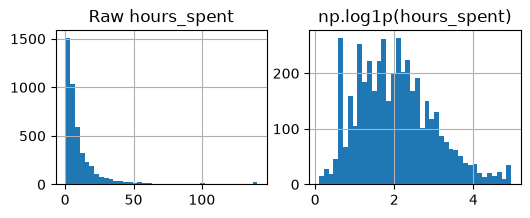

In [7]:
y = train_df["hours_spent"]
y_log1p = np.log1p(y)

print(f"Raw skew: {y.skew():.3f} | log1p skew: {y_log1p.skew():.3f}")
print("Quantiles:", y.quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]).round(2).to_dict())
print(f"Exact integer %: {(y % 1 == 0).mean() * 100:.2f}%")
print("Top 10 exact values:", y.value_counts().head(10).to_dict())

# Verify bucket boundaries IF auxiliary buckets exist
# print(train_df.groupby("hours_bucket")["hours_spent"].agg(["count", "min", "max"]))

# Plots:
fig, axes = plt.subplots(1, 2, figsize=(6, 2))
y.hist(bins=40, ax=axes[0]); axes[0].set_title("Raw hours_spent")
y_log1p.hist(bins=40, ax=axes[1]); axes[1].set_title("np.log1p(hours_spent)")

In [8]:
# Missing Values
col_df[["dtype", "non_null", "nulls", "null_pct", "nunique"]].sort_values("null_pct", ascending=False).T

# About 15 columns have null values

,is_mobile_responsive,num_js_files_loaded,num_internal_pages,page_weight_kb,load_time_ms,comment_line_ratio,avg_file_length,pct_primary_language,pct_code_in_first_commit,churn_ratio,project_category,is_clone_or_tutorial,is_multiplayer,mentions_ai_api,has_custom_art,lines_deleted_total,num_commits,project_id,lines_added_total,pct_commits_late_night,pct_commits_weekend,commit_cadence,project_span_days,active_commit_days,avg_commit_msg_length,primary_language,num_languages,num_dependencies,framework,num_test_files,has_ci_config,num_commit_authors,median_lines_per_commit,num_branches,num_merge_commits,num_source_files,lines_of_code,num_directories,max_dir_depth,pct_generic_commit_msgs,max_lines_in_one_commit,asset_size_mb,num_font_files,num_3d_model_files,num_audio_files,num_image_files,has_database,has_dockerfile,has_backend,has_tests,uses_game_engine,readme_has_install_instructions,readme_num_code_blocks,has_docs_folder,has_license,readme_num_headings,readme_word_count,has_custom_domain,url_is_live,hosting_type,readme_num_images,description_word_count,stars,forks,num_issues,num_pull_requests,num_releases,is_forked_from_template,author_prior_projects,author_account_age_years,hours_spent,log_hours,hours_bucket
dtype,object,float64,float64,float64,float64,float64,float64,float64,float64,float64,str,object,object,object,object,int64,int64,str,int64,float64,float64,str,int64,int64,float64,str,int64,int64,str,int64,bool,int64,float64,int64,int64,int64,int64,int64,int64,float64,int64,float64,int64,int64,int64,int64,bool,bool,bool,bool,bool,bool,int64,bool,bool,int64,int64,bool,bool,str,int64,int64,int64,int64,int64,int64,int64,bool,str,str,float64,float64,str
non_null,3077,3077,3077,3151,3151,4306,4306,4306,4314,4479,4495,4495,4495,4497,4498,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500
nulls,1423,1423,1423,1349,1349,194,194,194,186,21,5,5,5,3,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
null_pct,31.62,31.62,31.62,29.98,29.98,4.31,4.31,4.31,4.13,0.47,0.11,0.11,0.11,0.07,0.04,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
nunique,2,28,21,217,64,1487,3111,2210,2616,2683,6,2,2,2,2,357,323,4500,633,886,936,3,552,139,2642,22,12,100,18,38,2,45,1038,35,91,205,267,163,16,729,474,484,39,41,54,283,2,2,2,2,2,2,28,2,2,46,724,2,2,17,24,394,40,25,54,87,31,2,4,4,525,1857,4


In [9]:
# See the "object" dtype columns (all are actually boolean) and their nulls
obj_cols_with_nulls = col_df[col_df["dtype"] == "object"].index
train_df.sort_index(axis=1, key=lambda cols: [f"{int(col not in obj_cols_with_nulls.to_list())}{col}" for col in cols]).iloc[(-train_df[obj_cols_with_nulls].isna().sum(axis=1)).argsort(kind="stable")].head(6)

,has_custom_art,is_clone_or_tutorial,is_mobile_responsive,is_multiplayer,mentions_ai_api,active_commit_days,asset_size_mb,author_account_age_years,author_prior_projects,avg_commit_msg_length,avg_file_length,churn_ratio,comment_line_ratio,commit_cadence,description_word_count,forks,framework,has_backend,has_ci_config,has_custom_domain,has_database,has_dockerfile,has_docs_folder,has_license,has_tests,hosting_type,hours_bucket,hours_spent,is_forked_from_template,lines_added_total,lines_deleted_total,lines_of_code,load_time_ms,log_hours,max_dir_depth,max_lines_in_one_commit,median_lines_per_commit,num_3d_model_files,num_audio_files,num_branches,num_commit_authors,num_commits,num_dependencies,num_directories,num_font_files,num_image_files,num_internal_pages,num_issues,num_js_files_loaded,num_languages,num_merge_commits,num_pull_requests,num_releases,num_source_files,num_test_files,page_weight_kb,pct_code_in_first_commit,pct_commits_late_night,pct_commits_weekend,pct_generic_commit_msgs,pct_primary_language,primary_language,project_category,project_id,project_span_days,readme_has_install_instructions,readme_num_code_blocks,readme_num_headings,readme_num_images,readme_word_count,stars,url_is_live,uses_game_engine
2455,NaN,NaN,NaN,NaN,NaN,107,2.9,<1,6+,21.1956,152.8571,0.5071,0.0155,daily,1487,0,nextjs,True,False,False,False,False,False,False,False,github-repo,<10,3.6,True,48600,24600,5400,NaN,1.2856,4,4400,11.0,0,0,1,46,652,37,69,1,15,NaN,0,NaN,2,151,0,0,35,0,NaN,0.0118,0.0890,0.2040,0.1457,0.9948,JavaScript,NaN,630e653719,475,True,5,5,3,649,0,True,False
2970,NaN,NaN,True,NaN,NaN,114,2.9,1-2,1-2,21.3162,154.4857,0.5079,0.0154,daily,779,0,nextjs,True,False,False,False,False,False,False,False,vercel,<10,1.6,True,48400,24600,5400,900.0,0.4386,4,4400,11.0,0,0,3,49,662,37,69,1,15,2.0,0,14.0,2,156,0,0,35,0,2890.0,0.0119,0.0952,0.2069,0.1443,0.9948,JavaScript,NaN,a170240213,627,True,5,5,3,649,0,True,False
306,False,NaN,NaN,NaN,False,121,0.0,3-5,0,26.1183,48.8462,0.5280,0.0567,sporadic,94,0,none,False,True,False,False,False,False,True,False,mod-platform,<10,8.0,False,3000,1600,600,NaN,2.0794,7,500,8.0,0,0,1,31,174,0,12,0,1,NaN,0,NaN,2,5,0,0,13,0,NaN,0.1669,0.2126,0.1839,0.2663,0.8850,Java,NaN,3721f3ffd5,2337,True,0,3,0,44,0,True,False
1403,True,NaN,True,NaN,NaN,6,19.8,3-5,3-5,65.8000,69.1176,0.2039,0.1515,frequent,93,0,godot,False,False,False,False,False,False,True,False,itch,10-30,23.5,False,20500,4200,1200,400.0,3.1570,3,7200,342.0,0,15,1,1,25,0,9,1,13,2.0,0,3.0,1,0,0,0,17,0,680.0,0.1303,0.2400,0.1200,0.1200,1.0000,GDScript,NaN,7fee82d52a,8,True,0,6,10,327,0,True,True
2773,True,NaN,NaN,NaN,False,7,0.1,1-2,0,14.9091,17.1429,0.2553,0.0042,sporadic,45,0,none,False,False,False,False,False,False,True,False,mod-platform,<10,8.0,False,1300,300,200,NaN,2.0794,8,400,130.0,0,0,1,2,12,0,13,0,12,NaN,0,NaN,1,1,0,1,14,0,NaN,0.2598,0.7500,0.2500,0.6364,1.0000,Java,NaN,847342172b,92,True,0,6,0,270,0,True,False
0,False,False,NaN,False,False,15,0.1,1-2,0,38.7273,107.2791,0.3438,0.0199,daily,46,0,nextjs,True,False,False,True,True,False,True,False,hack-club,30-100,32.2,False,8500,2900,4600,NaN,3.4726,5,1600,128.5,0,0,1,1,44,20,23,0,8,NaN,0,NaN,5,0,0,0,43,0,NaN,0.0312,0.4545,0.2045,0.0227,0.9506,TypeScript,app,535ce026f7,56,True,5,17,0,401,2,False,False


In [11]:
set(train_df["project_id"].to_list()).intersection(set(train_df["project_id"].to_list()))

{'1e3be579d2',
 '8abeb1f255',
 '78abc081ac',
 '4fd029f68b',
 '5378de56e9',
 '8216c74c78',
 '4c09600cc7',
 '7e95740536',
 'cebce2bb57',
 '7b637b544b',
 '0c9cc67b0f',
 '742ff9ba17',
 'c95fd0bbe3',
 'f79b0ad9da',
 'a4d183c374',
 '250bf3a52e',
 '4ca8011dcc',
 '1f1fbe480f',
 'e5de96d709',
 '206ab6c7ca',
 'afd65d3cad',
 '51bac75aab',
 'e15785d73e',
 '3da7e651f8',
 'c825e10ea0',
 '7dd88e9797',
 'c52b93b437',
 '8e0e77b562',
 'ac822659c4',
 '5f53d48af8',
 'a2c1d92dfd',
 '1738eee4fe',
 'a99075ee98',
 '0756ee1e86',
 'f831591147',
 '0d44318878',
 'a5bc6f2e10',
 '57e1a656e3',
 '807384b360',
 '08e2176939',
 'c50e9eb26c',
 'b68f2fb80c',
 '8cf6d42165',
 '41980d8783',
 'ce7cfcce5f',
 '2a042dc160',
 '7ab7f89840',
 'ad50105ecb',
 '8219b0407a',
 '8eacd889db',
 'a9b05cc2f1',
 '37caad7d8f',
 'cec7f840a8',
 'fafab27b39',
 '78fce77fab',
 '59420859df',
 '00f9f11b11',
 'dd8e8a9cb4',
 'bf094db8f9',
 '1eeb52ab0e',
 '841edbdc05',
 'd4820928b4',
 '547e55b388',
 '2f3b957e83',
 '543152cbe0',
 '2d48ea9cb4',
 '00e247d8

### Pre-Processing

## Modelling

## Final